In [ ]:
# 1. Create the hidden Kaggle directory
!mkdir -p ~/.kaggle

# 2. Move your uploaded API key into that directory
!cp kaggle.json ~/.kaggle/

# 3. Secure the file permissions (required by Kaggle)
!chmod 600 ~/.kaggle/kaggle.json


cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [ ]:
import pandas as pd

df = pd.read_csv('/content/crop_yield.csv')
display(df.head())

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909


In [ ]:
# Check dataset shape
print("Shape:", df.shape)

# Check column names
print("\nColumns:")
print(df.columns.tolist())

# Check data types
print("\nData Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Check unique values
print("\nUnique Crops:", df['Crop'].nunique())
print("Unique States:", df['State'].nunique())
print("Unique Seasons:", df['Season'].nunique())

Shape: (19689, 10)

Columns:
['Crop', 'Crop_Year', 'Season', 'State', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']

Data Types:
Crop                object
Crop_Year            int64
Season              object
State               object
Area               float64
Production           int64
Annual_Rainfall    float64
Fertilizer         float64
Pesticide          float64
Yield              float64
dtype: object

Missing Values:
Crop               0
Crop_Year          0
Season             0
State              0
Area               0
Production         0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yield              0
dtype: int64

Duplicate Rows: 0

Unique Crops: 55
Unique States: 30
Unique Seasons: 6


In [ ]:
print("\nYield Statistics:")
print(df['Yield'].describe())


Yield Statistics:
count    19689.000000
mean        79.954009
std        878.306193
min          0.000000
25%          0.600000
50%          1.030000
75%          2.388889
max      21105.000000
Name: Yield, dtype: float64


In [ ]:
# 1. Check the relationship between Production, Area and Yield

print("Correlation between numerical features:\n")

numeric_columns = [
    'Crop_Year',
    'Area',
    'Production',
    'Annual_Rainfall',
    'Fertilizer',
    'Pesticide',
    'Yield'
]

print(df[numeric_columns].corr()['Yield'].sort_values(ascending=False))


# 2. Show the rows with the highest Yield values

print("\nTop 10 highest Yield values:")
display(
    df[['Crop', 'Crop_Year', 'State', 'Area',
        'Production', 'Yield']]
    .sort_values('Yield', ascending=False)
    .head(10)
)


# 3. Calculate Production / Area

df['calculated_yield'] = df['Production'] / df['Area']

print("\nActual Yield vs Production/Area:")
display(
    df[['Production', 'Area', 'Yield', 'calculated_yield']]
    .head(10)
)


# 4. Check how close they are

difference = abs(df['Yield'] - df['calculated_yield'])

print("\nAverage difference:",
      difference.mean())

print("Maximum difference:",
      difference.max())

Correlation between numerical features:

Yield              1.000000
Production         0.570809
Annual_Rainfall    0.020761
Fertilizer         0.002862
Crop_Year          0.002539
Area               0.001858
Pesticide          0.001782
Name: Yield, dtype: float64

Top 10 highest Yield values:


,Crop,Crop_Year,State,Area,Production,Yield
13962,Coconut,2014,Telangana,439.0,9265095,21105.00000
5771,Coconut,2019,Andhra Pradesh,104027.0,1912224000,16935.05846
13406,Coconut,2013,Telangana,428.0,6956712,16254.00000
5425,Coconut,2018,Andhra Pradesh,104530.0,1571100000,15636.63231
3610,Coconut,2012,Andhra Pradesh,99825.0,1670659000,14794.63000
18015,Coconut,2012,Puducherry,1564.0,20297000,14410.51667
3052,Coconut,2009,Tamil Nadu,400466.0,5547100000,14134.65935
4742,Coconut,2016,Andhra Pradesh,102548.0,1415300000,13934.12250
2724,Coconut,2008,Tamil Nadu,389429.0,5362000000,13834.07258
3836,Coconut,2013,Andhra Pradesh,99066.0,1610007000,13712.57308



Actual Yield vs Production/Area:


,Production,Area,Yield,calculated_yield
0,56708,73814.0,0.796087,0.768255
1,4685,6637.0,0.710435,0.705891
2,22,796.0,0.238333,0.027638
3,126905000,19656.0,5238.051739,6456.298331
4,794,1739.0,0.420909,0.456584
5,9073,13587.0,0.643636,0.667771
6,1507,2979.0,0.465455,0.505874
7,904095,94520.0,9.919565,9.565118
8,5158,10098.0,0.461364,0.510794
9,14721,19216.0,0.615652,0.766080



Average difference: 5.9310010602739505
Maximum difference: 3733.9932541860217


In [ ]:
# Remove the temporary column we created earlier
df.drop(columns=['calculated_yield'], inplace=True)

# Show yield statistics for every crop
crop_yield_stats = (
    df.groupby('Crop')['Yield']
    .agg(['count', 'min', 'mean', 'median', 'max'])
    .sort_values('max', ascending=False)
)

display(crop_yield_stats)

,count,min,mean,median,max
Crop,,,,,
Coconut,172,0.000000,8652.000199,8466.315523,21105.000000
Maize,975,0.000000,3.427216,1.955455,989.870000
Onion,454,0.000000,13.247525,9.192846,381.420000
Cashewnut,134,0.000000,3.120438,0.462500,338.548966
Potato,628,0.000000,13.331718,10.175284,311.020000
Sugarcane,605,0.290000,51.727439,53.158158,165.000000
Banana,245,0.000000,26.851128,17.948750,126.387692
Cotton(lint),476,0.000000,1.797044,1.428365,95.993913
Bajra,524,0.208000,2.427462,1.035937,74.303077


In [ ]:
# Show the 20 highest yield records
print("Highest Yield Records:")

display(
    df[
        ['Crop', 'Crop_Year', 'Season', 'State',
         'Area', 'Production', 'Yield']
    ]
    .sort_values('Yield', ascending=False)
    .head(20)
)

Highest Yield Records:


,Crop,Crop_Year,Season,State,Area,Production,Yield
13962,Coconut,2014,Whole Year,Telangana,439.0,9265095,21105.00000
5771,Coconut,2019,Whole Year,Andhra Pradesh,104027.0,1912224000,16935.05846
13406,Coconut,2013,Whole Year,Telangana,428.0,6956712,16254.00000
5425,Coconut,2018,Whole Year,Andhra Pradesh,104530.0,1571100000,15636.63231
3610,Coconut,2012,Whole Year,Andhra Pradesh,99825.0,1670659000,14794.63000
18015,Coconut,2012,Whole Year,Puducherry,1564.0,20297000,14410.51667
3052,Coconut,2009,Whole Year,Tamil Nadu,400466.0,5547100000,14134.65935
4742,Coconut,2016,Whole Year,Andhra Pradesh,102548.0,1415300000,13934.12250
2724,Coconut,2008,Whole Year,Tamil Nadu,389429.0,5362000000,13834.07258
3836,Coconut,2013,Whole Year,Andhra Pradesh,99066.0,1610007000,13712.57308


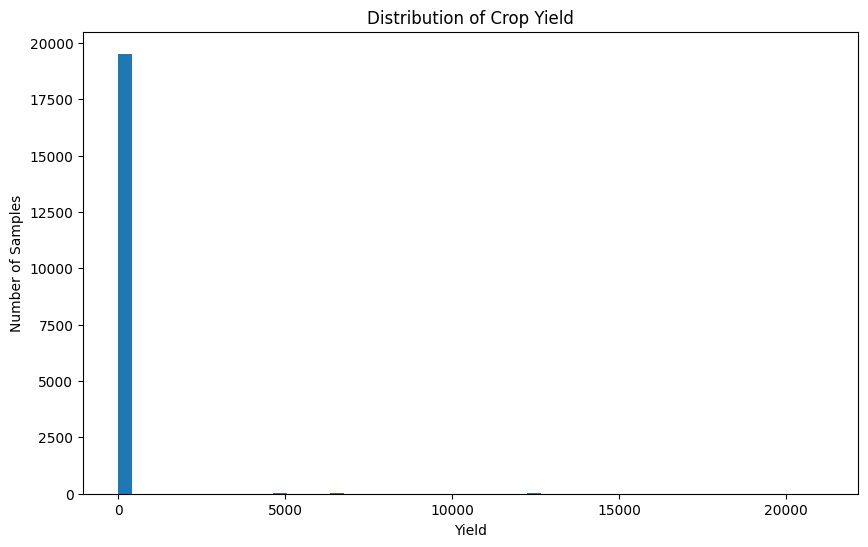

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(df['Yield'], bins=50)

plt.xlabel("Yield")
plt.ylabel("Number of Samples")
plt.title("Distribution of Crop Yield")

plt.show()

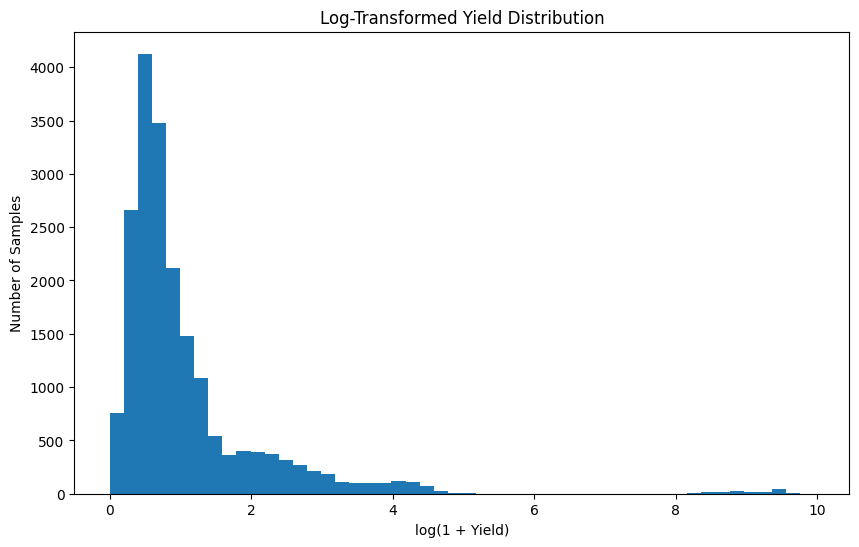

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(np.log1p(df['Yield']), bins=50)

plt.xlabel("log(1 + Yield)")
plt.ylabel("Number of Samples")
plt.title("Log-Transformed Yield Distribution")

plt.show()

In [ ]:
crop_mean_yield = (
    df.groupby('Crop')['Yield']
    .mean()
    .sort_values(ascending=False)
)

print(crop_mean_yield)

Crop
Coconut                  8652.000199
Sugarcane                  51.727439
Banana                     26.851128
Tapioca                    16.667301
Potato                     13.331718
Onion                      13.247525
Sweet potato                9.240788
Jute                        7.555393
Ginger                      6.442202
Mesta                       5.389204
Garlic                      4.544886
Maize                       3.427216
Turmeric                    3.325392
Cashewnut                   3.120438
Bajra                       2.427462
Rice                        2.218495
Tobacco                     2.110708
Dry chillies                2.078330
Arecanut                    2.073635
Wheat                       2.005086
Oilseeds total              1.995559
Cotton(lint)                1.797044
other oilseeds              1.789220
Barley                      1.595540
Peas & beans (Pulses)       1.393895
Groundnut                   1.360983
Sannhamp                    1.274

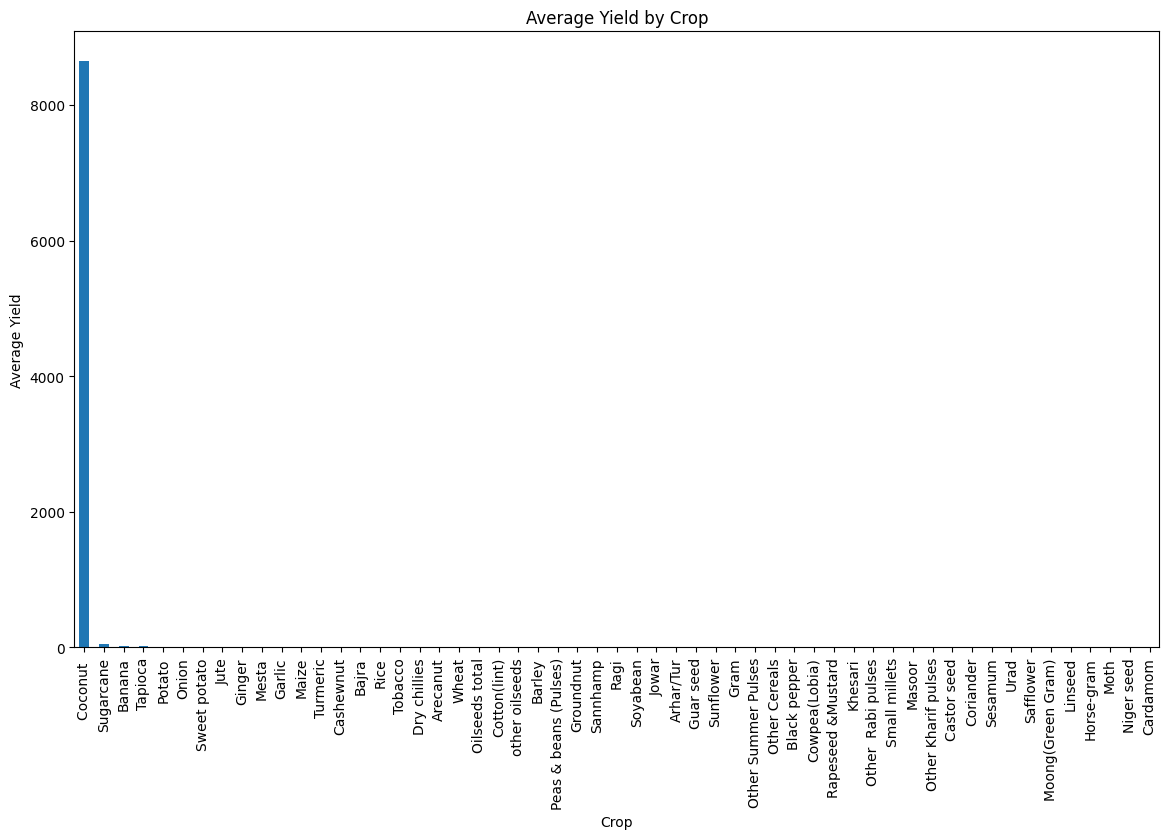

In [ ]:
plt.figure(figsize=(14, 8))

crop_mean_yield.plot(kind='bar')

plt.xlabel("Crop")
plt.ylabel("Average Yield")
plt.title("Average Yield by Crop")
plt.xticks(rotation=90)

plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Features we will use
features = [
    'Crop',
    'Crop_Year',
    'Season',
    'State',
    'Area',
    'Annual_Rainfall',
    'Fertilizer',
    'Pesticide'
]

# Input and target
X = df[features]
y = df['Yield']

# Categorical columns
categorical_features = [
    'Crop',
    'Season',
    'State'
]

# Numerical columns
numerical_features = [
    'Crop_Year',
    'Area',
    'Annual_Rainfall',
    'Fertilizer',
    'Pesticide'
]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nCategorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Input shape: (19689, 8)
Target shape: (19689,)

Categorical features:
['Crop', 'Season', 'State']

Numerical features:
['Crop_Year', 'Area', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 15751
Testing samples: 3938


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(
                handle_unknown='ignore'
            ),
            categorical_features
        ),
        (
            'numerical',
            'passthrough',
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# Create Random Forest Regressor
rf_yield_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_yield_model.fit(X_train, y_train)

print("Random Forest Yield Model trained successfully!")

Random Forest Yield Model trained successfully!


In [ ]:
y_pred_rf = rf_yield_model.predict(X_test)

print("First 10 predictions:")
print(y_pred_rf[:10])

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

First 10 predictions:
[ 3.93470623  1.44072723  6.61756544  0.86794735  0.51601878  0.47095225
  0.62525894  2.02260399 77.07549285  1.9358    ]

First 10 actual values:
[ 3.82        1.39535714  6.52272727  0.81285714  0.508       0.358
  0.74909091  1.83578947 75.314375    1.775     ]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_rf)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2 = r2_score(y_test, y_pred_rf)

print("Random Forest Yield Prediction Results")
print("---------------------------------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

Random Forest Yield Prediction Results
---------------------------------------
MAE : 9.330814424581522
RMSE: 125.81999590160878
R²  : 0.9802422819157968


In [ ]:
import numpy as np

y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

print("Original Yield:")
print(y_train.head())

print("\nLog-transformed Yield:")
print(y_train_log.head())

Original Yield:
19466    2.860000
17802    2.610000
7014     0.447273
14078    1.170769
8121     0.535789
Name: Yield, dtype: float64

Log-transformed Yield:
19466    1.350667
17802    1.283708
7014     0.369681
14078    0.775082
8121     0.429045
Name: Yield, dtype: float64


In [ ]:
rf_yield_log_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

rf_yield_log_model.fit(X_train, y_train_log)

print("Log-transformed Random Forest trained successfully!")

Log-transformed Random Forest trained successfully!


In [ ]:
y_pred_log = rf_yield_log_model.predict(X_test)

# Convert predictions back to original Yield scale
y_pred_log_original = np.expm1(y_pred_log)

print("First 10 predictions:")
print(y_pred_log_original[:10])

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

First 10 predictions:
[ 3.88178343  1.3197964   6.61404469  0.86295687  0.56122864  0.44630453
  0.63374843  2.02191958 74.04919     1.87953591]

First 10 actual values:
[ 3.82        1.39535714  6.52272727  0.81285714  0.508       0.358
  0.74909091  1.83578947 75.314375    1.775     ]


In [ ]:
mae_log = mean_absolute_error(
    y_test,
    y_pred_log_original
)

rmse_log = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_log_original
    )
)

r2_log = r2_score(
    y_test,
    y_pred_log_original
)

print("Log-Transformed Random Forest Results")
print("--------------------------------------")
print("MAE :", mae_log)
print("RMSE:", rmse_log)
print("R²  :", r2_log)

Log-Transformed Random Forest Results
--------------------------------------
MAE : 12.86951708001966
RMSE: 272.85315096000386
R²  : 0.9070829532460489


In [ ]:
mae_log = mean_absolute_error(
    y_test,
    y_pred_log_original
)

rmse_log = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_log_original
    )
)

r2_log = r2_score(
    y_test,
    y_pred_log_original
)

print("Log-Transformed Random Forest Results")
print("--------------------------------------")
print("MAE :", mae_log)
print("RMSE:", rmse_log)
print("R²  :", r2_log)

Log-Transformed Random Forest Results
--------------------------------------
MAE : 12.86951708001966
RMSE: 272.85315096000386
R²  : 0.9070829532460489


In [ ]:
print("Yield Model Comparison")
print("------------------------------")

print(f"Normal Random Forest")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

print("\nLog-Transformed Random Forest")
print(f"MAE  : {mae_log:.4f}")
print(f"RMSE : {rmse_log:.4f}")
print(f"R²   : {r2_log:.4f}")

Yield Model Comparison
------------------------------
Normal Random Forest
MAE  : 9.3308
RMSE : 125.8200
R²   : 0.9802

Log-Transformed Random Forest
MAE  : 12.8695
RMSE : 272.8532
R²   : 0.9071


In [ ]:
from xgboost import XGBRegressor

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [ ]:
xgb_yield_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', XGBRegressor(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        objective='reg:squarederror',
        n_jobs=-1
    ))
])

xgb_yield_model.fit(X_train, y_train)

print("XGBoost Yield Model trained successfully!")

XGBoost Yield Model trained successfully!


In [ ]:
y_pred_xgb_yield = xgb_yield_model.predict(X_test)

print("First 10 XGBoost predictions:")
print(y_pred_xgb_yield[:10])

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

First 10 XGBoost predictions:
[ 1.1208746   1.9951899   9.214778    1.0306008   1.1640688   0.4021413
  0.69151866  2.3154812  69.642624    1.4466239 ]

First 10 actual values:
[ 3.82        1.39535714  6.52272727  0.81285714  0.508       0.358
  0.74909091  1.83578947 75.314375    1.775     ]


In [ ]:
mae_xgb = mean_absolute_error(
    y_test,
    y_pred_xgb_yield
)

rmse_xgb = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_xgb_yield
    )
)

r2_xgb = r2_score(
    y_test,
    y_pred_xgb_yield
)

print("XGBoost Yield Prediction Results")
print("--------------------------------")
print("MAE :", mae_xgb)
print("RMSE:", rmse_xgb)
print("R²  :", r2_xgb)

XGBoost Yield Prediction Results
--------------------------------
MAE : 14.5465813741576
RMSE: 244.60952050841132
R²  : 0.9253234641161897


In [ ]:
print("FINAL YIELD MODEL COMPARISON")
print("=" * 40)

print("\nRandom Forest")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

print("\nLog Random Forest")
print(f"MAE  : {mae_log:.4f}")
print(f"RMSE : {rmse_log:.4f}")
print(f"R²   : {r2_log:.4f}")

print("\nXGBoost")
print(f"MAE  : {mae_xgb:.4f}")
print(f"RMSE : {rmse_xgb:.4f}")
print(f"R²   : {r2_xgb:.4f}")

FINAL YIELD MODEL COMPARISON

Random Forest
MAE  : 9.3308
RMSE : 125.8200
R²   : 0.9802

Log Random Forest
MAE  : 12.8695
RMSE : 272.8532
R²   : 0.9071

XGBoost
MAE  : 14.5466
RMSE : 244.6095
R²   : 0.9253


In [ ]:
def predict_yield(
    crop,
    crop_year,
    season,
    state,
    area,
    annual_rainfall,
    fertilizer,
    pesticide
):

    input_data = pd.DataFrame([{
        'Crop': crop,
        'Crop_Year': crop_year,
        'Season': season,
        'State': state,
        'Area': area,
        'Annual_Rainfall': annual_rainfall,
        'Fertilizer': fertilizer,
        'Pesticide': pesticide
    }])

    prediction = rf_yield_model.predict(input_data)

    return prediction[0]

In [ ]:
predicted = predict_yield(
    "Arecanut",
    1997,
    "Whole Year",
    "Assam",
    73814.0,
    2051.4,
    7024878.38,
    22882.34
)

print("Predicted Yield:", predicted)

Predicted Yield: 0.8771263629549995


In [ ]:
import joblib

joblib.dump(
    rf_yield_model,
    "crop_yield_prediction_model.pkl"
)

print("Crop Yield model saved successfully!")

Crop Yield model saved successfully!


In [ ]:
yield_feature_names = [
    'Crop',
    'Crop_Year',
    'Season',
    'State',
    'Area',
    'Annual_Rainfall',
    'Fertilizer',
    'Pesticide'
]

joblib.dump(
    yield_feature_names,
    "yield_feature_names.pkl"
)

print("Yield feature names saved successfully!")

Yield feature names saved successfully!


In [ ]:
from google.colab import files

files.download('crop_yield_prediction_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>